# Lab 1: The Bare-Metal Perceptron & The Great Keras Race

_The specfication for this Deep Learning Refresher Lab can be found in `lab_spec.md`_

The objective of this lab is to implement a custom object-oriented neural network class using **only NumPy**. We'll later write tiny TensorFlow script and compare the two.

## Milestone 1: Synthesize Data & Handle Shapes

1.  Use `sklearn.datasets.make_moons(n_samples=400, noise=0.2, random_state=42)` to get your $X$ and $y$ arrays.
    
2.  **Crucial Step:** Check the shape of $y$. By default, scikit-learn outputs a 1D array of shape `(400,)`. If you perform matrix operations with this, NumPy will broadcast incorrectly and silently ruin your math. Explicitly reshape it to a 2D column vector of shape `(400, 1)`.
    
3.  Use `matplotlib` to plot $X$ to visualize the two interlocking moons.

In [1]:
import sklearn
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X, y = sklearn.datasets.make_moons(n_samples=400, noise=0.2, random_state=42)

In [3]:
y.shape

(400,)

In [4]:
y = y.reshape((400,1))

In [5]:
y.shape

(400, 1)

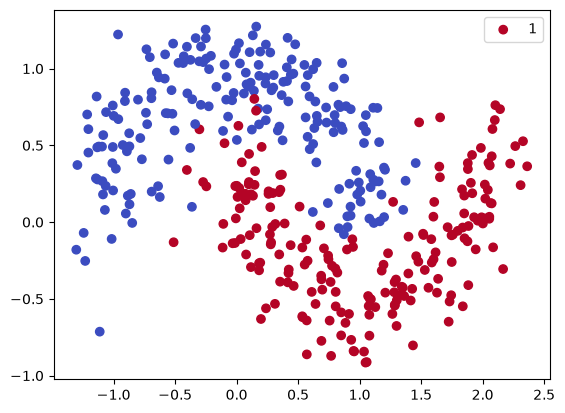

In [6]:
plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap='coolwarm')
plt.legend(y.ravel())
plt.show()

## Milestone 2: Initialize Your Weights Correctly

Create a class called `ScratchMLP` with an `__init__` method.

1.  Initialize `W1` using **He Initialization**: sample from a standard normal distribution (`np.random.randn`) and multiply it by $\sqrt{\frac{2}{\text{input\_dim}}}$.
    
2.  Initialize `b1` as a matrix of zeros with shape `(1, hidden_dim)`.
    
3.  Initialize `W2` using **Xavier Initialization**: sample from a normal distribution and multiply it by $\sqrt{\frac{1}{\text{hidden\_dim}}}$.
    
4.  Initialize `b2` as a matrix of zeros with shape `(1, 1)`.

## Milestone 3: Build the Layer Methods

Inside your class, implement these foundational math helper functions:

1.  `relu(Z)`: Returns $\max(0, Z)$.
    
2.  `relu_derivative(Z)`: Returns an array of $1$'s where $Z > 0$ and $0$'s elsewhere.
    
3.  `sigmoid(Z)`: Returns the standard sigmoid formula. _Tip:_ Wrap your input with `np.clip(Z, -500, 500)` before applying the exponent to prevent numerical overflow errors if weights grow large.
    

## Milestone 4: Write the Training Loop

1.  **`forward(X)`**: Compute $Z_1, A_1, Z_2, A_2$ sequentially. Store these variables as instance attributes (e.g., `self.A1`) because your backward pass will need to read them.
    
2.  **`backward(X, Y)`**: Implement the equations from the math section above. Return the final four gradient matrices (`dW1`, `db1`, `dW2`, `db2`).
    
3.  **`fit(X, Y, epochs, lr)`**: Loop through the number of epochs. In each iteration:
    
    -   Run the forward pass to get predictions ($A_2$).
        
    -   Calculate the Binary Cross-Entropy loss: $-\frac{1}{m} \sum [Y \log(A_2) + (1-Y) \log(1-A_2)]$. _Tip:_ Add a tiny epsilon value like `1e-15` inside the logs to avoid taking $\log(0)$.
        
    -   Call your backward pass to fetch gradients.
        
    -   Update your parameters using gradient descent: $Param = Param - (lr \times dParam)$.
        
    -   Append the loss to a list so you can return your training history.

In [23]:
class ScratchMLP:
    def __init__(self, input_dim, hidden_dim, output_dim=1):
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2/input_dim)
        self.b1 = np.zeros(shape=(1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(1/hidden_dim)
        self.b2 = np.zeros(shape=(1, output_dim))

    def relu(self, Z):
        return np.maximum(0,Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(int)

    def sigmoid(self, Z):
        return 1/(1+(np.exp(-np.clip(Z, -500, 500))))
    
    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self.relu(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.sigmoid(self.Z2)
        return self.A2

    def backward(self, X, Y):
        m = Y.shape[0]

        dZ2 = self.A2 - Y
        dW2 = np.dot(self.A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        dA1 = np.dot(dZ2, self.W2.T)

        dZ1 = dA1 * self.relu_derivative(self.Z1)
        dW1 = np.dot(X.T, dZ1) /m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m
        return dW1, db1, dW2, db2

    def fit(self, X, Y, epochs, lr):
        loss_list = []
        for i in range(epochs):
            preds = self.forward(X)

            m = Y.shape[0]
            eps = 1e-15
            bce_loss = - np.sum(Y * np.log(preds + eps) + (1-Y) * np.log(1 - preds + eps)) / m

            dW1, db1, dW2, db2 = self.backward(X, Y)

            self.W1 = self.W1 - (lr * dW1) 
            self.b1 = self.b1 - (lr * db1) 
            self.W2 = self.W2 - (lr * dW2) 
            self.b2 = self.b2 - (lr * db2) 

            loss_list.append(bce_loss)

            if i % 50 == 0:
                print(f'Epoch: {i}, Loss: {bce_loss}, W1: {self.W1}, b1: {self.b1}, W2: {self.W2}, b2: {self.b2}')

        return loss_list
            

## Milestone 5: The Keras Validation

1.  Build an identical network using `tf.keras.Sequential`.
    
2.  Add a `Dense` layer with 4 units and `'relu'` activation, followed by a `Dense` layer with 1 unit and `'sigmoid'` activation.
    
3.  Compile it using the standard `tf.keras.optimizers.SGD(learning_rate=0.1)` optimizer and `'binary_crossentropy'` loss.
    
4.  Train both models for 1,500 epochs with a learning rate of 0.1. Plot both loss logs on a single line chart to verify if your scratch math mirrors Keras!

In [8]:
import tensorflow as tf

In [9]:
model_keras = tf.keras.Sequential([
    tf.keras.Input((2,)),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_keras.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate = 0.1),
    loss='binary_crossentropy'
)

In [11]:
model_keras.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
keras_losses = model_keras.fit(X, y, epochs = 1500)

Epoch 1/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.5867
Epoch 2/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5072
Epoch 3/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4586 
Epoch 4/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4258 
Epoch 5/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4012
Epoch 6/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3820 
Epoch 7/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3673 
Epoch 8/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3558
Epoch 9/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3476 
Epoch 10/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3395 
Epoch 11/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3329
Epoch 12/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3278 
Epoch 13/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3241 
Epoch 14/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3223 
Epoch 15/1500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [24]:
model_scratch = ScratchMLP(2, 4)
scratch_losses = model_scratch.fit(X, y, epochs=1500, lr=0.1)

Epoch: 0, Loss: 1.4641189236472507, W1: [[-0.26601782  2.70152702  0.18609525  2.37945383]
 [ 0.85648857 -1.58000423  0.44463602 -0.12182124]], b1: [[-0.00849401 -0.00430766  0.00331485 -0.02011022]], W2: [[ 0.48192987]
 [ 0.00521287]
 [ 0.54430456]
 [-0.57341654]], b2: [[0.01639408]]
Epoch: 50, Loss: 0.4808137397298134, W1: [[-0.22468531  2.71599668  0.21326419  2.33798366]
 [ 0.68970552 -1.74360632  0.17146507  0.02391582]], b1: [[-0.21516557  0.03685092 -0.22507149 -0.02956498]], W2: [[ 0.05005329]
 [ 0.81308548]
 [ 0.43105423]
 [-0.36878535]], b2: [[-0.47176374]]
Epoch: 100, Loss: 0.42399761555746257, W1: [[-0.23095041  2.68265792  0.20426714  2.36620541]
 [ 0.71220419 -1.91755133  0.13506297  0.15227747]], b1: [[-0.18675805  0.12003873 -0.26674802 -0.03915909]], W2: [[-0.16226258]
 [ 1.06372558]
 [ 0.43735884]
 [-0.54062868]], b2: [[-0.74637357]]
Epoch: 150, Loss: 0.38585995549940094, W1: [[-0.2601681   2.64037237  0.22093953  2.39777967]
 [ 0.7886218  -2.06744361  0.12122787  0.2

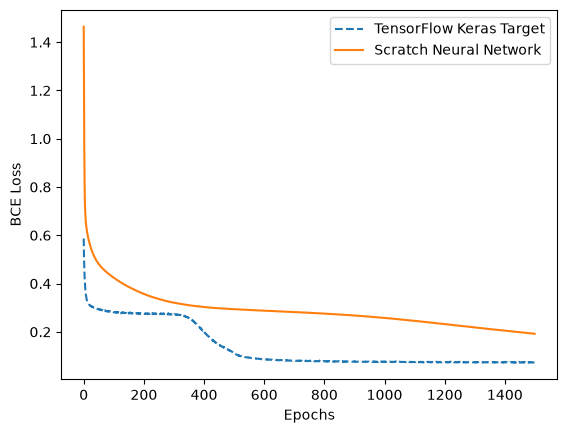

In [28]:
plt.plot(keras_losses.history['loss'], label='TensorFlow Keras Target', linestyle='--')
plt.plot(scratch_losses, label='Scratch Neural Network')
plt.xlabel('Epochs')
plt.ylabel('BCE Loss')
plt.legend()
plt.show()